本笔记本将继续进行：
- 三个宏观数据，以及外汇储备，政府债务/GDP，一共五个数据之间的双因子相关性矩阵
- 五个宏观因子之间的VIF多重共线性检测
- 回归所有宏观因子与政策事件dummies，并检查hypothesis test
- 检查残差自相关，异方差，残差与汇率相关性

下面读取汇率、五个宏观因子和事件变量，在完整月历上构造汇率滞后一期，再提取共同非缺失样本。数据目录为 `data/2_regression_monthly`，训练期为 2012-01 至 2024-12；汇率使用文件中的月度对数变化率，宏观因子保留现有单位；样本内常数事件列不入模，完全相同的事件列合并并保留名称。

This notebook will continue with:

- The pairwise correlation matrix among the three macro data series, foreign exchange reserves, and government debt/GDP — five series in total
- VIF multicollinearity checks among the five macro factors
- Regressing all macro factors on policy event dummies, and checking hypothesis tests
- Checking residual autocorrelation, heteroskedasticity, and correlation between residuals and the exchange rate

Next, read the exchange rate, the five macro factors, and the event variables, construct a one-period lag of the exchange rate on the full monthly calendar, and then extract the common non-missing sample. The data directory is `data/2_regression_monthly`, and the training period is 2012-01 to 2024-12; the exchange rate uses the monthly log change rate from the file, and the macro factors retain their existing units; event columns that are constant within the sample are not included in the model, and identical event columns are merged while retaining their names.

In [1]:
# import packages
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.graphics.tsaplots import plot_acf


In [2]:
# set paths, files
DATA = Path("data/2_regression_monthly")
if not DATA.is_dir():
    DATA = Path("../data/2_regression_monthly")
TRAIN_START, TRAIN_END = "2012-01-31", "2024-12-31"
calendar = pd.date_range(TRAIN_START, TRAIN_END, freq="ME")
FACTOR_FILES = {
    "CPI": "headline_cpi_log_change_monthly.csv",
    "GDP growth change": "gdp_annual_pct_change_monthly.csv",
    "Trade balance change": "trade_balance_annual_pct_change_monthly.csv",
    "FX reserves": "fx_reserves_log_change_monthly.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_monthly.csv",
}
factors = list(FACTOR_FILES)

def read_monthly(filename, usecols=None):
    frame = pd.read_csv(DATA / filename, usecols=usecols)
    frame.index = pd.to_datetime(frame.pop("date"))
    return frame.reindex(calendar).astype(float)

macro = pd.DataFrame({name: read_monthly(file, [0, 1]).iloc[:, 0]
                      for name, file in FACTOR_FILES.items()})
fx = read_monthly("USDSLE_monthly.csv", [0, 1]).iloc[:, 0].rename("fx_change")
events = read_monthly("Sierra_Leone_Policy_Event_Dummies_monthly.csv")
sample = pd.concat([fx, fx.shift(1).rename("fx_lag1"), macro, events], axis=1).dropna()

# Identical event columns share one coefficient.
groups = {}
for name in events:
    values = sample[name]
    if values.nunique() > 1:
        groups.setdefault(tuple(values), []).append(name)
policy_X = pd.DataFrame(index=sample.index)
policy_sources = {}
for pattern, names in groups.items():
    month = sample.index[np.asarray(pattern) == 1][0]
    term = f"P_{month:%Y_%m}"
    policy_X[term] = pattern
    policy_sources[term] = " + ".join(names)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")

然后，计算五个宏观因子的 Pearson 相关矩阵，并绘制热力图。使用与回归相同的完整样本；相关系数范围为 −1 至 1，色标固定在该范围。

Next, calculate the Pearson correlation matrix of the five macro factors and draw a heat map. Use the same complete sample as in the regression analysis; the correlation coefficient ranges from -1 to 1, and the color scale is fixed within this range.

,CPI,GDP growth change,Trade balance change,FX reserves,Government debt / GDP
CPI,1,0.0764243,0.22456,-0.148002,-0.0312548
GDP growth change,0.0764243,1,0.357729,0.0590224,0.0921785
Trade balance change,0.22456,0.357729,1,-0.0613397,-0.182627
FX reserves,-0.148002,0.0590224,-0.0613397,1,-0.0530205
Government debt / GDP,-0.0312548,0.0921785,-0.182627,-0.0530205,1


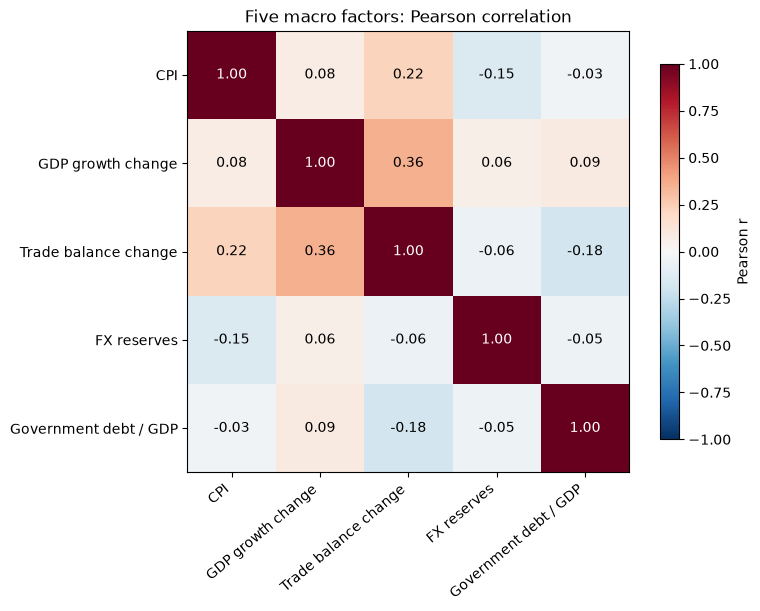

In [3]:
factor_sample = sample[factors]
correlation_matrix = factor_sample.corr(method="pearson")
display(correlation_matrix)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
chart = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = np.arange(len(factors))
ax.set_xticks(ticks, labels=factors, rotation=40, ha="right")
ax.set_yticks(ticks, labels=factors)
for i in ticks:
    for j in ticks:
        value = correlation_matrix.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else "black")
ax.set_title("Five macro factors: Pearson correlation")
fig.colorbar(chart, ax=ax, label="Pearson r", shrink=0.85)
plt.show()

宏观因子的双因子相关性矩阵中，除了对角数据以外，最大的相关性数值为0.36，是GDP growth和trade balance之间的相关性，约为0.36，小于阈值0.8，因此可以继续下一步。这里笔者认为，相关性高于其他因子的主要原因是，塞拉利昂的GDP有很大一部分受到进出口贸易的影响。

In the two-factors correlation matrix of 5 macro factors, apart from the diagonal data, the highest correlation value is 0.36, which is the correlation between GDP growth and trade balance, approximately 0.36, and is less than the threshold of 0.8. Therefore, we can proceed to the next step. Here, the author believes that the main reason for the correlation being higher than that of other factors is that a large part of Sierra Leone's GDP is influenced by import and export trade.

然后，计算五个宏观因子的 VIF，列出达到提示阈值的变量。其中，VIF 辅助回归包含截距，输入仅为五个宏观因子；提示阈值为 `VIF >= 5`。
Calculating the VIF for the five macro factors and list the variables that reach the warning threshold. Here, VIF in the regression analysis includes the intercept, and the input variables are only the five macro factors; the warning threshold is `VIF >= 5`.

In [4]:
VIF_THRESHOLD = 5.0
vif_X = sm.add_constant(factor_sample, has_constant="add")
vif_table = pd.DataFrame({
    "VIF": [variance_inflation_factor(vif_X.to_numpy(), i + 1)
            for i in range(len(factors))]
}, index=pd.Index(factors, name="factor"))
vif_table["VIF_ge_5"] = vif_table["VIF"] >= VIF_THRESHOLD
display(vif_table)

,VIF,VIF_ge_5
factor,,
CPI,1.07362,False
GDP growth change,1.19348,False
Trade balance change,1.2743,False
FX reserves,1.03792,False
Government debt / GDP,1.07307,False


下面估计“汇率变化率＝截距＋滞后一期汇率变化率＋五个同期宏观因子＋事件项＋残差”，并检验连续项系数及五个宏观因子的联合假设。另列出事件系数与对应名称。

设置与假设：
- OLS 估计系数；`alpha=0.05`，采用 HAC(12) 标准误、Bartlett 权重、有限样本缩放和渐近正态 z 检验。
- 单项原假设为系数等于 0；五个宏观因子的单项 p 值使用 Holm 校正，截距与 AR 项使用未校正 p 值；置信区间为逐项 95% 区间。
- 联合原假设为五个宏观因子系数同时等于 0，使用 HAC Wald 检验。
- 单月事件项使对应月份残差为 0，常规 HAC 标准误可能低估其不确定性，因此事件项只报告系数，不报告显著性。
- R²、调整后 R² 和 RMSE 均为样本内指标。

The following estimates "exchange rate change rate = intercept + lagged one-period exchange rate change rate + five concurrent macro factors + event term + residual", and tests the coefficients of consecutive terms and the joint hypothesis of the five macro factors. Additionally, lists the event coefficients and corresponding names.

Settings and Hypotheses:
- OLS estimated coefficients; `alpha = 0.05`, using HAC(12) standard errors, Bartlett weights, finite sample scaling, and asymptotically normal z-tests.
- The single null hypothesis is that the coefficient is equal to 0; the individual p-values of the five macro factors use Holm correction, while the intercept and AR term use uncorrected p-values; the confidence intervals are 95% intervals for each item.
- The joint null hypothesis is that the coefficients of the five macro factors are simultaneously equal to 0, using HAC Wald test.
- Single-month event terms make the residual of the corresponding month equal to 0. The conventional HAC standard errors may underestimate its uncertainty, so event terms only report coefficients, not significance.
- R², adjusted R², and RMSE are all sample internal indicators.

In [5]:
ALPHA, HAC_LAGS = 0.05, 12
continuous = ["fx_lag1", *factors]
y = sample["fx_change"]
X = sm.add_constant(pd.concat([sample[continuous], policy_X], axis=1),
                    has_constant="add")
ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
    use_t=False,
)
display(pd.DataFrame({
    "n": [int(ols.nobs)], "parameters": [len(ols.params)],
    "R2": [ols.rsquared], "adjusted_R2": [ols.rsquared_adj],
    "RMSE": [np.sqrt(np.mean(ols.resid ** 2))],
}, index=["AR(1) + five factors + events"]))

terms = ["const", *continuous]
ci = hac.conf_int(alpha=ALPHA).loc[terms]
coefficient_table = pd.DataFrame({
    "coefficient": hac.params.loc[terms], "HAC_SE": hac.bse.loc[terms],
    "z": hac.tvalues.loc[terms], "p_HAC": hac.pvalues.loc[terms],
    "CI95_low": ci[0], "CI95_high": ci[1],
})
coefficient_table["p_Holm_5_factors"] = np.nan
coefficient_table.loc[factors, "p_Holm_5_factors"] = multipletests(
    coefficient_table.loc[factors, "p_HAC"], method="holm"
)[1]
coefficient_table["reject_5pct"] = coefficient_table["p_HAC"] < ALPHA
coefficient_table.loc[factors, "reject_5pct"] = (
    coefficient_table.loc[factors, "p_Holm_5_factors"] < ALPHA
)
display(coefficient_table)

R = np.eye(X.shape[1])[[X.columns.get_loc(name) for name in factors]]
joint = hac.wald_test(R, use_f=False, scalar=True)
display(pd.DataFrame({
    "chi2": [float(joint.statistic)], "df": [len(factors)],
    "p_HAC": [float(joint.pvalue)], "reject_5pct": [joint.pvalue < ALPHA],
}, index=["All five macro coefficients = 0"]))
policy_table = pd.DataFrame({
    "source_events": pd.Series(policy_sources), "coefficient": ols.params[policy_X.columns],
    "month": [policy_X.index[policy_X[name].eq(1)][0].strftime("%Y-%m")
              for name in policy_X],
})
display(policy_table)

,n,parameters,R2,adjusted_R2,RMSE
AR(1) + five factors + events,155,12,0.532932,0.497004,3.2925


,coefficient,HAC_SE,z,p_HAC,CI95_low,CI95_high,p_Holm_5_factors,reject_5pct
const,-0.0263524,0.33817,-0.0779264,0.937887,-0.689154,0.636449,NaN,False
fx_lag1,-0.162354,0.10016,-1.62094,0.10503,-0.358664,0.0339566,NaN,False
CPI,1.0413,0.303465,3.43137,0.000600538,0.446521,1.63608,0.00300269,True
GDP growth change,-0.00210419,0.00191559,-1.09845,0.272006,-0.00585867,0.0016503,0.527862,False
Trade balance change,0.0011541,0.000671345,1.71908,0.0855998,-0.000161716,0.00246991,0.342399,False
FX reserves,-0.107443,0.06825,-1.57425,0.115429,-0.24121,0.0263247,0.346286,False
Government debt / GDP,0.0827914,0.0741096,1.11715,0.263931,-0.0624608,0.228044,0.527862,False


,chi2,df,p_HAC,reject_5pct
All five macro coefficients = 0,24.4469,5,0.000178123,True


,source_events,coefficient,month
P_2015_11,D_IMF_ECF_REVIEW_2015,-6.23018,2015-11
P_2016_06,D_Brexit referendum_2016,32.4303,2016-06
P_2021_08,D_REDENOM_ANNOUNCE_2021 + D_SDR_ALLOCATION_2021,3.30607,2021-08
P_2023_06,D_IMF_ECF_REVIEW_A_2023,-20.3907,2023-06
P_2023_11,D_IMF_ECF_REVIEW_B_2023,-1.92627,2023-11


#### <u>**回归结果较好。**</u> <u>**The regression results are fairly good.**</u>

在加入额外的宏观因子变量后，整体 R-square（Rs）提升至 0.533，调整后的 Rs 达到 0.497。其中，回归中影响最大的是 CPI，其 p_HAC 在 1% 水平上非常显著，说明 CPI 加速会导致本币贬值，符合 PPP 理论。**第一个回归模型未选择 CPI 作为因子的原因是：对于贸易导向型经济体塞拉利昂而言，汇率与通胀之间的因果关系难以明确（即究竟是通胀导致外汇贬值，还是外汇贬值导致通胀）。** 由于此前的回归排除了 CPI 并加入了更多贸易因素，结果发现大部分因子无法解释外汇变动；而此次回归发现 CPI 与汇率之间存在强相关关系，后续将继续探索 CPI 与外汇变动之间的相关性。

After additional macroeconomic factor variables were included, the overall R-squared (Rs) increased to 0.533, and the adjusted Rs reached 0.497. Among the factors, CPI has the largest effect in the regression: its p_HAC is highly significant at the 1% level, indicating that CPI acceleration leads to local currency depreciation, consistent with PPP theory. **The reason the first regression model did not select CPI as a factor is that, for Sierra Leone as a trade-oriented economy, the causal direction between the exchange rate and inflation cannot be clearly determined (i.e., whether inflation causes exchange rate depreciation or exchange rate depreciation causes inflation).** Because the previous regression excluded CPI and added more trade-related factors, it found that most factors could not explain exchange rate movements. This regression finds a strong correlation between CPI and the exchange rate, and subsequent work will continue to explore the correlation between CPI and exchange rate movements.


其他变量方面，GDP 增速、贸易差额、外汇储备和政府债务中，除贸易差额在 10% 水平上边缘显著（p = 0.085）外，其余变量的 p 值均不显著。**但联合检验 Wald test 得到的 p_HAC 为 0.00017，强于单个 CPI 因子的 p 值**，说明五个因子作为整体对汇率具有很强的解释力。

For the other variables—GDP growth, trade balance, foreign exchange reserves, and government debt—the p-values are insignificant except for the trade balance, which is marginally significant at the 10% level (p = 0.085). **However, the joint Wald test yielded p_HAC = 0.00017, which is stronger than the p-value of the individual CPI factor**, indicating that the five factors as a group have strong explanatory power for the exchange rate.


事件冲击同样会影响外汇波动。不过，由于对应事件是通过筛选 USDSLE 外汇数据中某些日期的巨额波动来确定的，因此不能排除以下情况：**同一天还发生了另一件真正导致汇率巨额波动的事件，或者根本不存在事件，但实际用于回归的却是另一事件，从而导致伪回归**。因此，后续仍需继续寻找对应的事件冲击。

Event shocks also affect exchange rate fluctuations. However, because the corresponding events were identified by screening for large daily fluctuations in the USDSLE exchange rate data, it cannot be ruled out that **another event that truly caused the large exchange rate fluctuation occurred on the same day, or that no event existed, while a different event was actually used in the regression, leading to spurious regression**. Therefore, further work is still needed to identify the corresponding event shocks.


接下来使用 Breusch–Godfrey 检验残差自相关，并绘制残差 ACF。`alpha=0.05`；BG 原假设为截至给定阶数的残差相关系数均为 0，检验阶数为 1、6、12，三个经典 LM 检验的 p 值作 Holm 校正；ACF 展示 24 阶及参考置信带，保留事件月份以维持时间间隔。

Next, use the Breusch–Godfrey test for residual autocorrelation and plot the residual ACF. `alpha = 0.05`; the BG null hypothesis is that the residual correlation coefficients up to the given lag order are all zero. The test is run at lag orders 1, 6, and 12, and the p-values of the three classical LM tests are Holm-corrected. The ACF is displayed up to lag 24 with reference confidence bands, and event months are retained to preserve the time spacing.

,LM,p_LM,p_Holm,reject_5pct
lags,,,,
1,1.67748,0.19526,0.585779,False
6,4.40263,0.622361,1,False
12,5.54814,0.937128,1,False


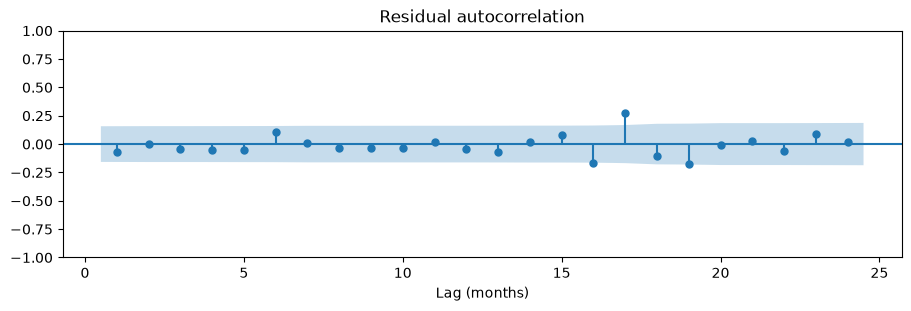

In [6]:
BG_LAGS, ACF_LAGS = (1, 6, 12), 24
residuals = ols.resid
bg_rows = []
for lag in BG_LAGS:
    bg = acorr_breusch_godfrey(ols, nlags=lag, result_object=True)
    bg_rows.append({"lags": lag, "LM": bg.lm, "p_LM": bg.lmpval})
bg_tests = pd.DataFrame(bg_rows).set_index("lags")
bg_tests["p_Holm"] = multipletests(bg_tests["p_LM"], method="holm")[1]
bg_tests["reject_5pct"] = bg_tests["p_Holm"] < ALPHA
display(bg_tests)

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
plot_acf(residuals, lags=ACF_LAGS, zero=False, alpha=ALPHA, ax=ax)
ax.set(title="Residual autocorrelation", xlabel="Lag (months)")
plt.show()

然后，使用 Koenker 版本的 Breusch–Pagan 检验残差异方差。设置变量方面，`alpha=0.05`、`robust=True`；原假设为误差方差不随列出的连续解释变量变化；使用非事件月份，辅助变量为截距、汇率滞后项和五个宏观因子，避免单月事件强制零残差的影响。

Then, use the Koenker version of the Breusch-Pagan test to examine the variance of the residuals. In terms of variable settings, `alpha=0.05` and `robust=True`; the null hypothesis is that the variance of the errors does not change with the listed continuous explanatory variables; using non-event months, the auxiliary variables are the intercept, the lagged exchange rate term, and five macro factors, to avoid the influence of single-month events forcing the residuals to be zero.

In [7]:
non_event = ~policy_X.any(axis=1)
bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(
    residuals.loc[non_event], X.loc[non_event, ["const", *continuous]], robust=True
)
bp_test = pd.DataFrame({
    "n": [int(non_event.sum())], "LM": [bp_lm], "p_LM": [bp_p],
    "reject_5pct": [bp_p < ALPHA],
}, index=["Koenker BP: non-event months"])
display(bp_test)

,n,LM,p_LM,reject_5pct
Koenker BP: non-event months,150,6.36186,0.383898,False


最后，计算残差与当期、滞后一期汇率变化率的 Pearson 相关系数。使用同一回归样本；含截距 OLS 下，残差与当期因变量的相关系数满足 `sqrt(1-R²)`，与已纳入模型的滞后项按构造正交。

Last step, calculate the Pearson correlation coefficient between the residuals and the current and lagged one-period exchange rate changes. Using the same regression sample; with intercept OLS, the correlation coefficient between the residuals and the current dependent variable satisfies `sqrt(1-R²)`, and it is constructed orthogonally with the lagged terms already included in the model.

In [8]:
residual_fx_correlation = pd.DataFrame({
    "correlation": [residuals.corr(y), residuals.corr(sample["fx_lag1"])],
    "OLS_identity": [np.sqrt(1 - ols.rsquared), 0.0],
}, index=["Residual vs current FX change", "Residual vs lagged FX change"])
display(residual_fx_correlation)

,correlation,OLS_identity
Residual vs current FX change,0.683424,0.683424
Residual vs lagged FX change,-7.08011e-16,0
